# Hand Gesture Recognition Using Classical Computer Vision and Machine Learning

<img src="../hand_gesture.gif" alt="Gesture Demo" width="450" height="280">


### 20 Different Gestures with total 24000 images

<img src="../dataset-cover.png" alt="Gesture Demo" width="450" height="280">

[Download the dataset from Kaggle](https://www.kaggle.com/datasets/aryarishabh/hand-gesture-recognition-dataset/data)

## 1. Data Import and Exploratory Data Analysis (EDA)

In [1]:
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Add the parent directory of the notebook to Python path
sys.path.append(str(Path().resolve().parent))

# Set the path to the dataset directory
train_dir = Path('../data/Train')
test_dir = Path('../data/Test')


### Exploratory Data Analysis (EDA)

In [2]:
# Check the number of Classes and Samples Per Class

def count_images_per_class(directory):
    class_counts = {}
    for class_folder in sorted(directory.iterdir()):
        if class_folder.is_dir():
            count = len(list(class_folder.glob("*.jpg")))
            class_counts[class_folder.name] = count
    return class_counts

train_counts = count_images_per_class(train_dir)
test_counts = count_images_per_class(test_dir)

print(" Training Samples Per Class:")
for k, v in train_counts.items():
    print(f"Class {k}: {v} images")

print("\n Testing Samples Per Class:")
for k, v in test_counts.items():
    print(f"Class {k}: {v} images")


 Training Samples Per Class:
Class 0: 900 images
Class 1: 900 images
Class 10: 900 images
Class 11: 900 images
Class 12: 900 images
Class 13: 900 images
Class 14: 900 images
Class 15: 900 images
Class 16: 900 images
Class 17: 900 images
Class 18: 900 images
Class 19: 900 images
Class 2: 900 images
Class 3: 900 images
Class 4: 900 images
Class 5: 900 images
Class 6: 900 images
Class 7: 900 images
Class 8: 900 images
Class 9: 900 images

 Testing Samples Per Class:
Class 0: 300 images
Class 1: 300 images
Class 10: 300 images
Class 11: 300 images
Class 12: 300 images
Class 13: 300 images
Class 14: 300 images
Class 15: 300 images
Class 16: 300 images
Class 17: 300 images
Class 18: 300 images
Class 19: 300 images
Class 2: 300 images
Class 3: 300 images
Class 4: 300 images
Class 5: 300 images
Class 6: 300 images
Class 7: 300 images
Class 8: 300 images
Class 9: 300 images


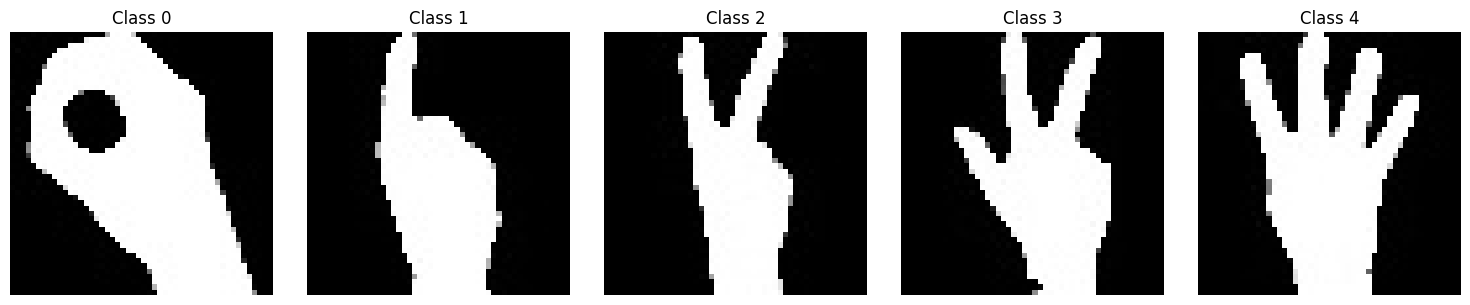

In [3]:
# Show some sample images from a few classes

def show_class_samples(directory, class_ids=[0, 1, 2, 3, 4]):
    plt.figure(figsize=(15, 3))
    for i, class_id in enumerate(class_ids):
        folder = directory / str(class_id)
        image_paths = list(folder.glob("*.jpg"))

        if not image_paths:
            continue

        img = cv2.imread(str(image_paths[0]))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, len(class_ids), i + 1)
        plt.imshow(img_rgb)
        plt.title(f"Class {class_id}")
        plt.axis("off")
        
    plt.tight_layout()
    plt.show()

show_class_samples(train_dir, class_ids=[0, 1, 2, 3, 4])


## 2. Data Preprocessing

Class 0 - Original image shape: (50, 50)


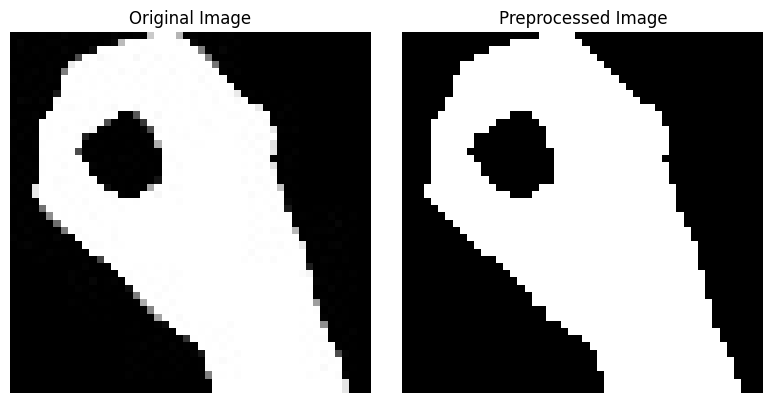

Class 1 - Original image shape: (50, 50)


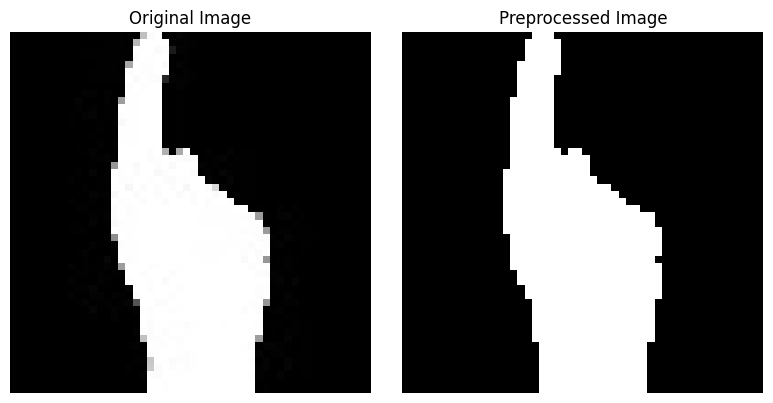

Class 2 - Original image shape: (50, 50)


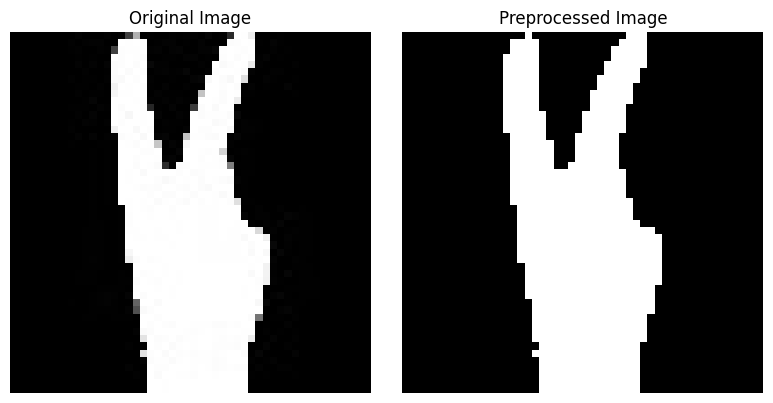

Class 3 - Original image shape: (50, 50)


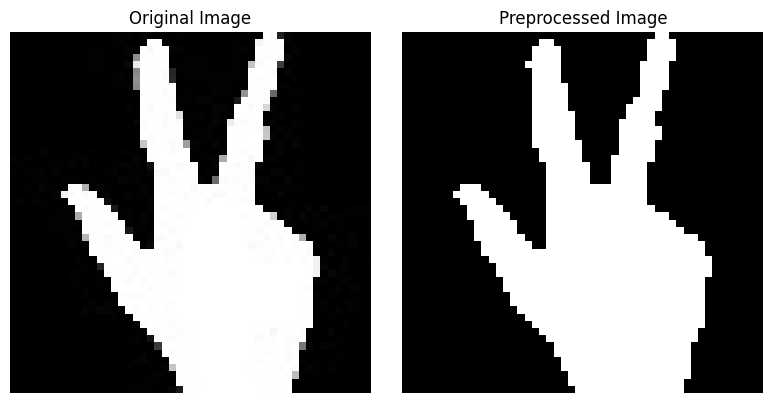

Class 4 - Original image shape: (50, 50)


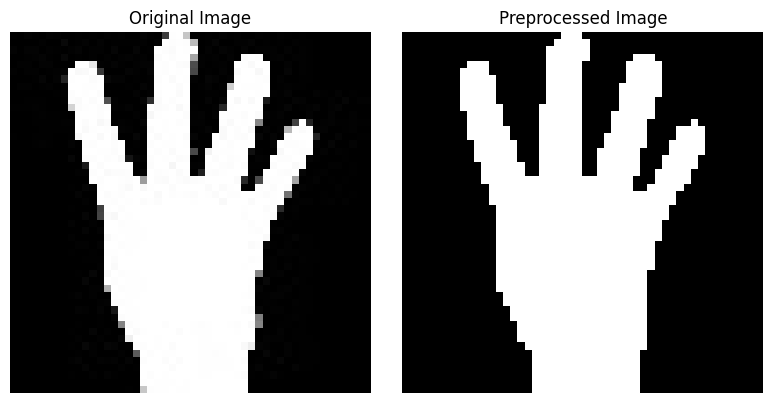

Class 5 - Original image shape: (50, 50)


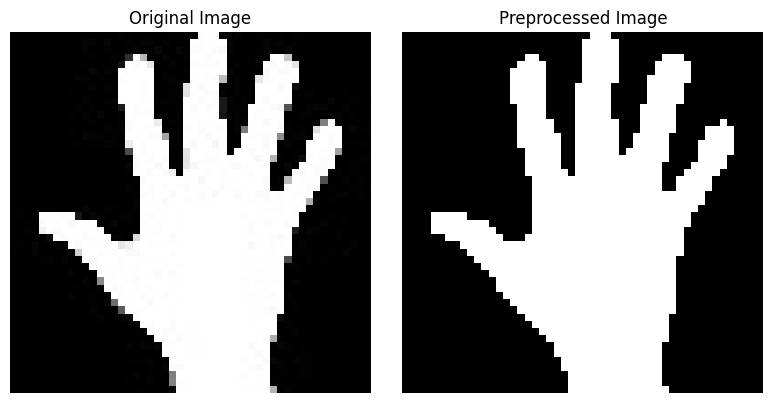

Class 6 - Original image shape: (50, 50)


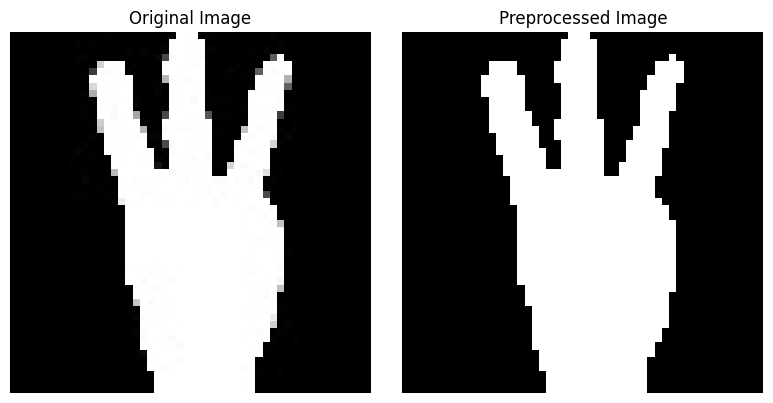

Class 7 - Original image shape: (50, 50)


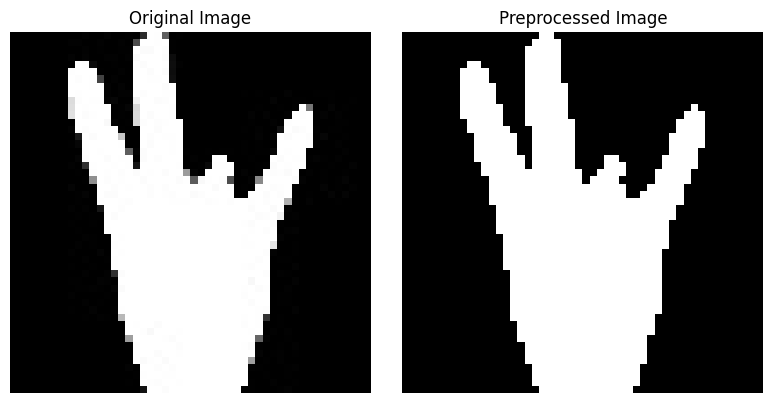

Class 8 - Original image shape: (50, 50)


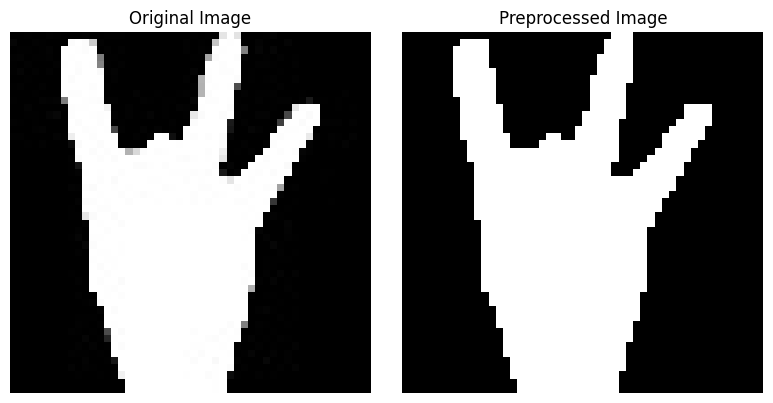

Class 9 - Original image shape: (50, 50)


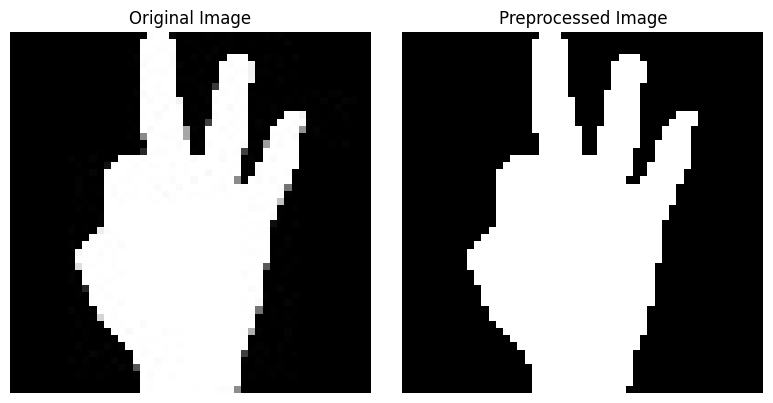

Class 10 - Original image shape: (50, 50)


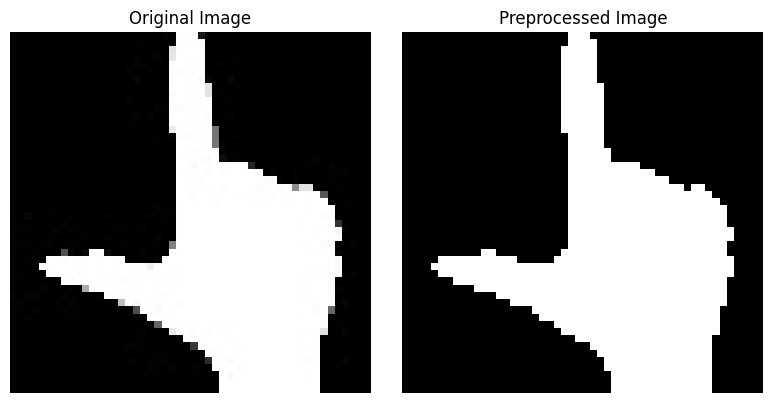

Class 11 - Original image shape: (50, 50)


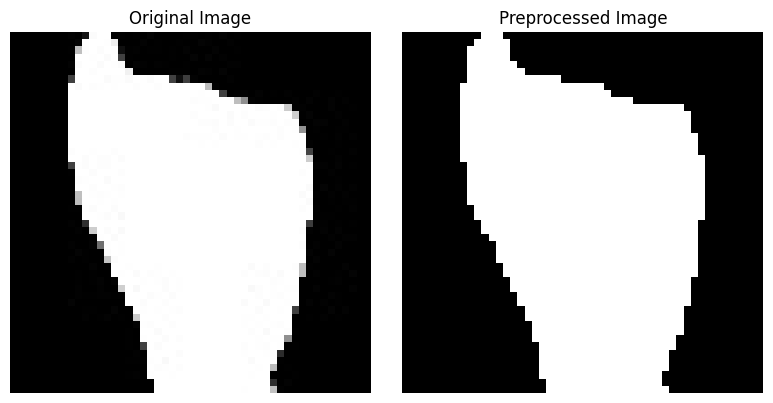

Class 12 - Original image shape: (50, 50)


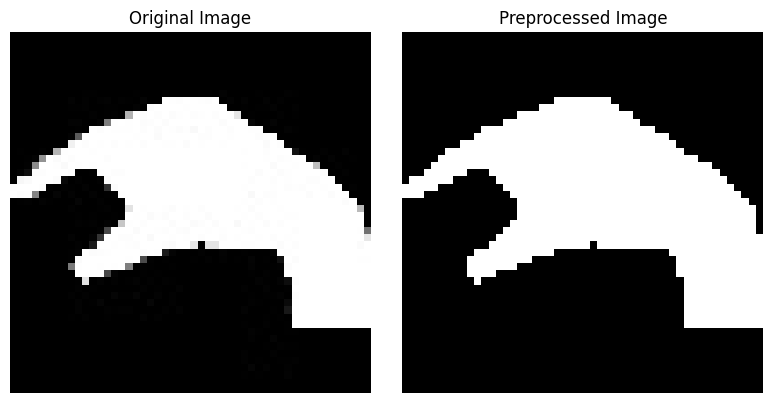

Class 13 - Original image shape: (50, 50)


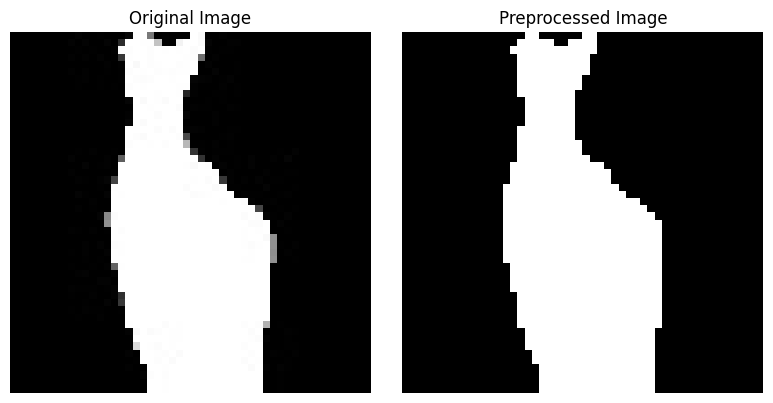

Class 14 - Original image shape: (50, 50)


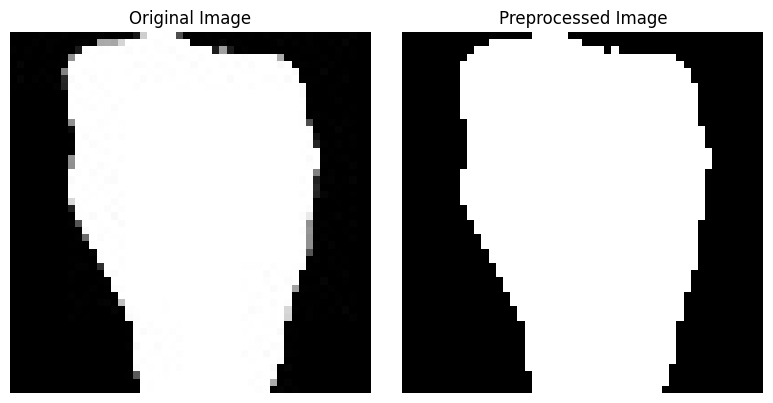

Class 15 - Original image shape: (50, 50)


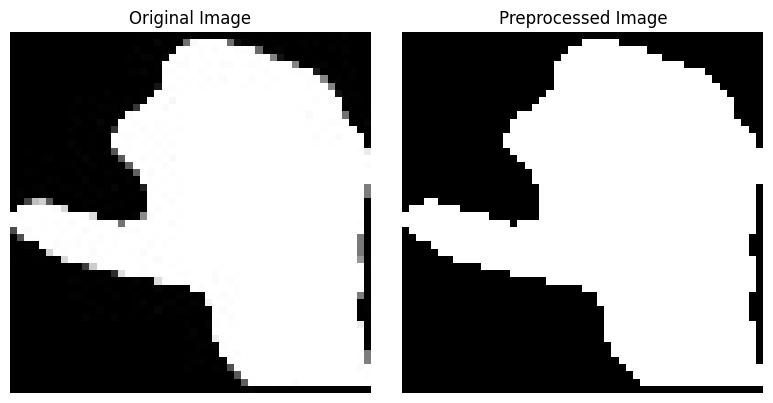

Class 16 - Original image shape: (50, 50)


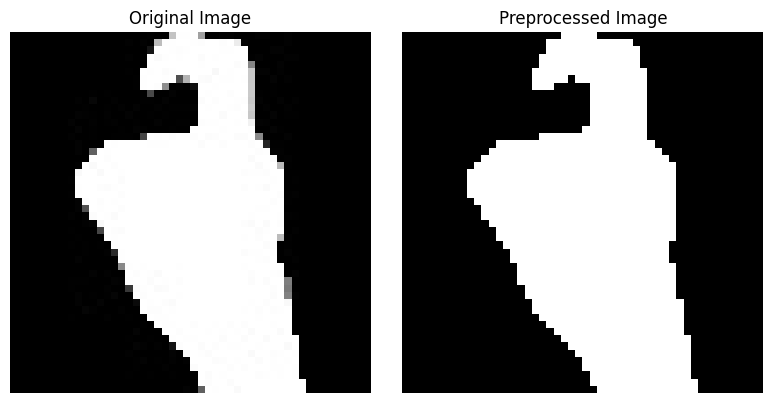

Class 17 - Original image shape: (50, 50)


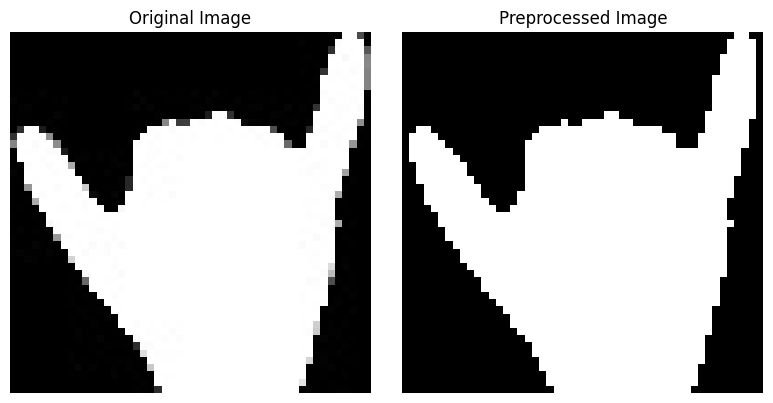

Class 18 - Original image shape: (50, 50)


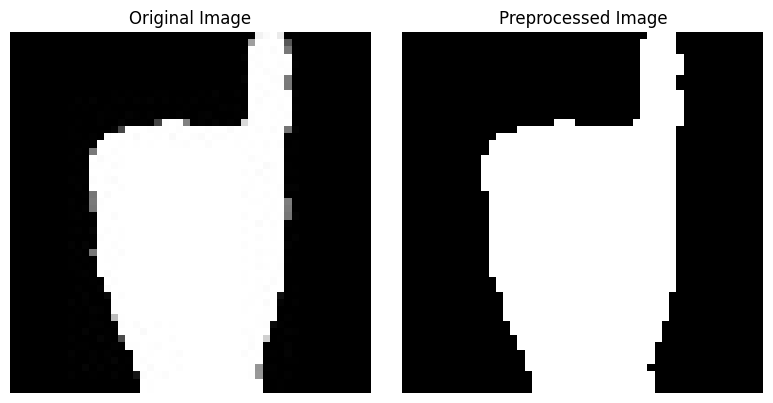

Class 19 - Original image shape: (50, 50)


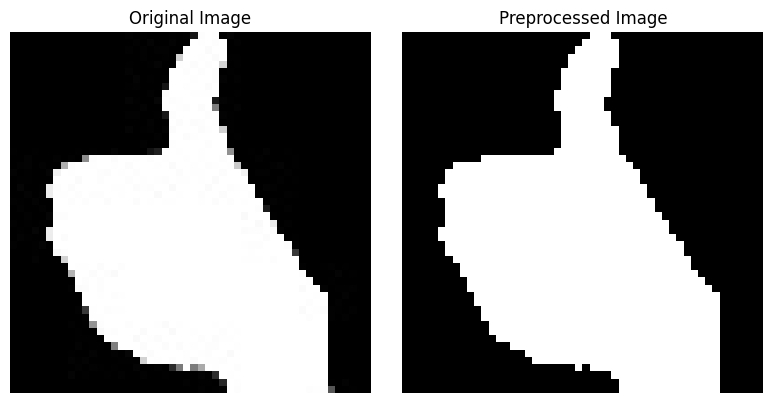

In [4]:
# Preprocess an example image.
from utils.preprocess import preprocess_image


def display_preprocessed_image(img, threshold_value):
    """Display the original and preprocessed images side by side."""
    # Preprocess image
    processed = preprocess_image(img, threshold_value=threshold_value)

    # Plot side-by-side
    plt.figure(figsize=(8, 4))

    # Original image
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    # Preprocessed image
    plt.subplot(1, 2, 2)
    plt.imshow(processed, cmap='gray')
    plt.title("Preprocessed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


# Print 1 image from each class.
for class_id in range(20):
    image_path = str(train_dir / str(class_id) / '1.jpg')
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    print(f"Class {class_id} - Original image shape: {img.shape}")
    display_preprocessed_image(img, threshold_value=150)


## 3. Feature Extraction from training dataset

In [5]:
from utils.features import extract_features
from utils.preprocess import preprocess_image


# Extract features from a few sample images
sample_features = []
sample_labels = []

for label in os.listdir(train_dir):  # No sorting here
    if not label.isdigit():
        continue  # Skip non-numeric labels (like .DS_Store)

    class_path = train_dir / label
    image_paths = list(class_path.glob("*.jpg"))

    for image_path in image_paths:
        img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        processed = preprocess_image(img)
        features = extract_features(processed)

        sample_features.append(features)
        sample_labels.append(int(label))

# Display the shape of the feature vector
if sample_features:
    print(f"Feature vector shape: {np.array(sample_features).shape}")
else:
    print("No features extracted.")

# Display feature shape and first few samples
print(f"Total samples: {len(sample_features)}")
print("Feature vector (first 10 samples):")
for i in range(min(10, len(sample_features))):
    print(f"Label: {sample_labels[i]}, Features: {sample_features[i]}")


# Print all sample features and labels
# print("\nAll sample features and labels:")
# for i in range(len(sample_features)):
#     print(f"Label: {sample_labels[i]}, Features: {sample_features[i]}")


Feature vector shape: (18000, 8)
Total samples: 18000
Feature vector (first 10 samples):
Label: 18, Features: [0, 3.0977988565149692, 6.841437666493843, 9.724854488649722, 9.94254996203791, 9.999999999997867, 9.999989282013612, -9.999999999999591]
Label: 18, Features: [1, 3.0973178054794515, 6.900342734105212, 9.72896777356613, 9.907648762416562, 9.999999999995365, 9.999972246247898, 9.999999999999485]
Label: 18, Features: [0, 3.1072517054744546, 6.914735422706069, 9.746101707692194, 9.94277891097198, 9.99999999999797, 9.999987841277072, -9.999999999999744]
Label: 18, Features: [0, 3.1046681699404655, 6.8741283196540905, 9.752436473417719, 9.95723437431874, 9.999999999998778, 9.999993961162644, -9.999999999999666]
Label: 18, Features: [0, 3.099326375208002, 6.8495196220975165, 9.770319729609977, 9.955834617263685, 9.999999999998737, 9.999992938139094, -9.999999999999867]
Label: 18, Features: [0, 3.1046633011682356, 6.8740410904964575, 9.748043248808191, 9.941834321063899, 9.99999999999

## 4. Gesture Classification

### Training KNN classifier model for the gesture classification

KNN Training Accuracy: 99.37%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       900
           1       0.97      0.91      0.94       900
           2       1.00      1.00      1.00       900
           3       1.00      1.00      1.00       900
           4       1.00      1.00      1.00       900
           5       1.00      1.00      1.00       900
           6       1.00      1.00      1.00       900
           7       1.00      1.00      1.00       900
           8       1.00      1.00      1.00       900
           9       1.00      1.00      1.00       900
          10       1.00      1.00      1.00       900
          11       1.00      1.00      1.00       900
          12       1.00      1.00      1.00       900
          13       0.92      0.98      0.95       900
          14       1.00      1.00      1.00       900
          15       1.00      1.00      1.00       900
          16       1.00    

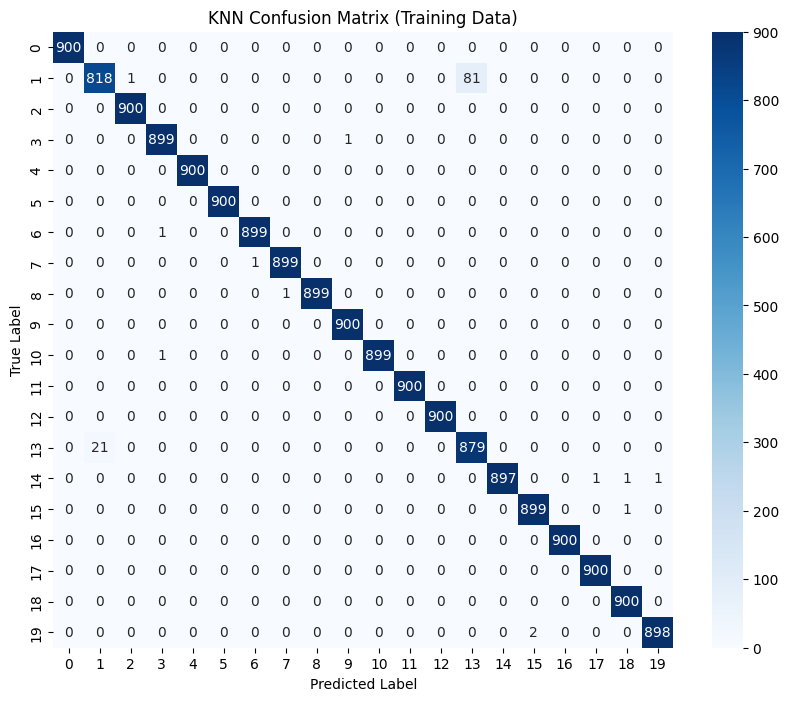

In [6]:
from utils.classification import train_knn, predict_knn
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

# Train on extracted features
knn_model = train_knn(sample_features, sample_labels, k=3)

# Predict on training data (for testing accuracy)
train_preds = predict_knn(knn_model, sample_features)

# Evaluate
accuracy = accuracy_score(sample_labels, train_preds)
print(f"KNN Training Accuracy: {accuracy * 100:.2f}%")

# Print classification report
print("\nClassification Report:")
print(classification_report(sample_labels, train_preds))

# Generate confusion matrix
cm = confusion_matrix(sample_labels, train_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("KNN Confusion Matrix (Training Data)")
plt.show()

### Training SVM model for the gesture classification

SVM Training Accuracy: 98.03%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       900
           1       0.95      0.74      0.83       900
           2       1.00      1.00      1.00       900
           3       1.00      1.00      1.00       900
           4       1.00      1.00      1.00       900
           5       1.00      1.00      1.00       900
           6       0.99      0.99      0.99       900
           7       1.00      0.99      1.00       900
           8       1.00      1.00      1.00       900
           9       1.00      1.00      1.00       900
          10       1.00      1.00      1.00       900
          11       1.00      0.95      0.97       900
          12       1.00      1.00      1.00       900
          13       0.79      0.96      0.87       900
          14       0.95      1.00      0.97       900
          15       1.00      0.97      0.99       900
          16       1.00    

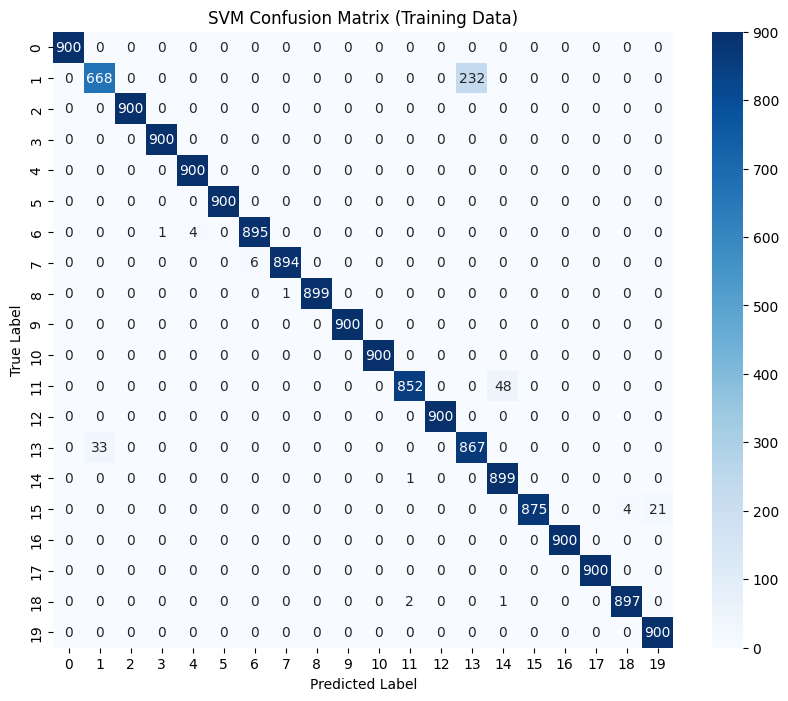

In [7]:
from utils.classification import train_svm, predict_svm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# Train SVM model
scaler = StandardScaler()
scaled_features = scaler.fit_transform(sample_features)

svm_model = train_svm(scaled_features, sample_labels, kernel='rbf', C=1.0)

# Predict on training data
svm_preds = predict_svm(svm_model, scaled_features)

# Evaluate
accuracy = accuracy_score(sample_labels, svm_preds)
print(f"SVM Training Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(sample_labels, svm_preds))

# Confusion matrix
cm = confusion_matrix(sample_labels, svm_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("SVM Confusion Matrix (Training Data)")
plt.show()


### Training ResNet18 model for the gesture classification

/Users/anamolkhadka/opt/anaconda3/envs/hand_gesture/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/anamolkhadka/opt/anaconda3/envs/hand_gesture/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch [1/5], Loss: 0.0322
Epoch [2/5], Loss: 0.0008
Epoch [3/5], Loss: 0.0001
Epoch [4/5], Loss: 0.0000
Epoch [5/5], Loss: 0.0304
ResNet18 Training Accuracy: 99.57%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       900
           1       1.00      1.00      1.00       900
           2       1.00      1.00      1.00       900
           3       1.00      1.00      1.00       900
           4       1.00      1.00      1.00       900
           5       1.00      1.00      1.00       900
           6       1.00      0.99      0.99       900
           7       1.00      1.00      1.00       900
           8       1.00      1.00      1.00       900
           9       1.00      1.00      1.00       900
          10       1.00      1.00      1.00       900
          11       1.00      1.00      1.00       900
          12       1.00      1.00      1.00       900
          13       1.00      1.00      1.00       900


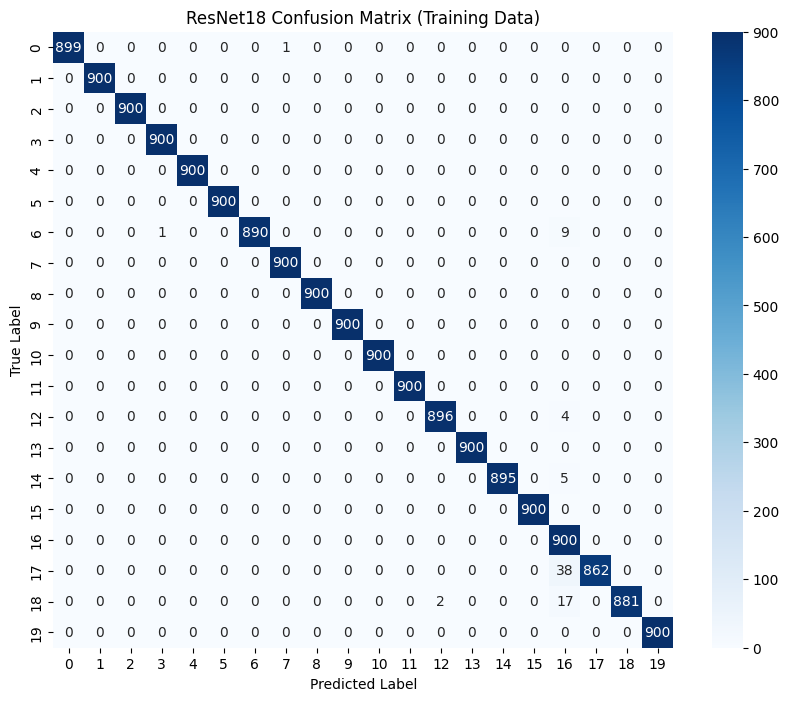

In [8]:
from utils.classification import train_resnet18, predict_resnet18
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Train ResNet18 model on training folder
resnet_model = train_resnet18(train_dir, epochs=5, batch_size=32, lr=0.001)

# Predict on training images
resnet_preds, resnet_true = predict_resnet18(resnet_model, train_dir)

# Evaluate performance
accuracy = accuracy_score(resnet_true, resnet_preds)
print(f"ResNet18 Training Accuracy: {accuracy * 100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(resnet_true, resnet_preds))

# Confusion Matrix
cm = confusion_matrix(resnet_true, resnet_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet18 Confusion Matrix (Training Data)")
plt.show()


## 5. Testing

### Extracting features from test dataset

In [9]:
# Extract features from the test dataset

# Collect test features and labels
test_features = []
test_labels = []

for label in os.listdir(test_dir):
    if not label.isdigit():
        continue
    class_path = test_dir / label
    image_paths = list(class_path.glob("*.jpg"))

    for image_path in image_paths:
        img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        processed = preprocess_image(img)
        features = extract_features(processed)

        test_features.append(features)
        test_labels.append(int(label))

# Display the shape of the test feature vector
if test_features:
    print(f"Test feature vector shape: {np.array(test_features).shape}")
else:
    print("No test features extracted.")

Test feature vector shape: (6000, 8)


### KNN Evaluation on Test Data

KNN Test Accuracy: 93.12%

KNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       300
           1       0.77      0.42      0.55       300
           2       1.00      1.00      1.00       300
           3       0.99      1.00      0.99       300
           4       1.00      1.00      1.00       300
           5       1.00      1.00      1.00       300
           6       0.98      0.99      0.99       300
           7       1.00      1.00      1.00       300
           8       1.00      1.00      1.00       300
           9       0.99      0.91      0.95       300
          10       1.00      1.00      1.00       300
          11       0.99      1.00      0.99       300
          12       1.00      1.00      1.00       300
          13       0.60      0.88      0.71       300
          14       1.00      1.00      1.00       300
          15       0.72      0.73      0.72       300
          16       0.94    

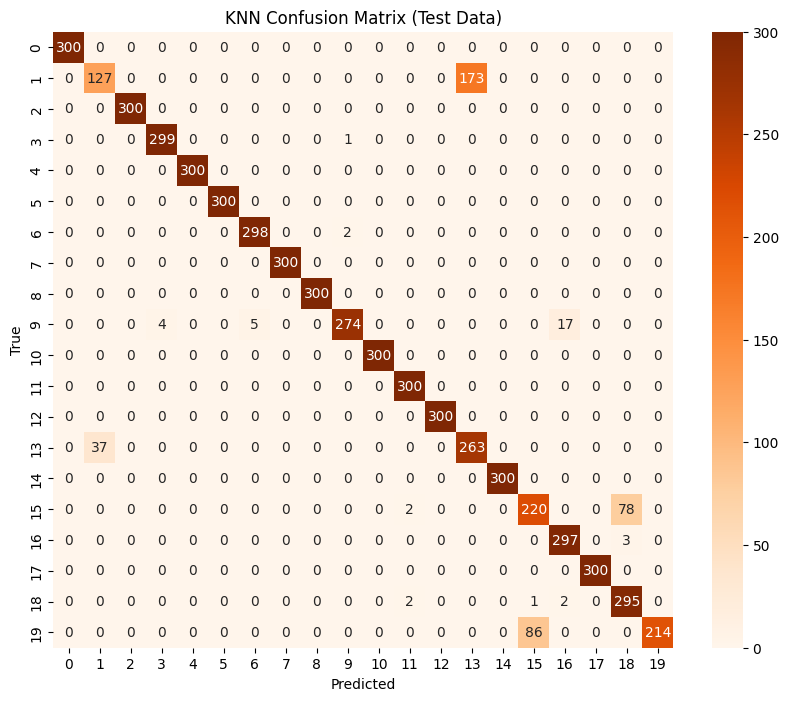

In [10]:
# Predict using KNN
knn_test_preds = predict_knn(knn_model, test_features)

# Evaluate
accuracy = accuracy_score(test_labels, knn_test_preds)
print(f"KNN Test Accuracy: {accuracy * 100:.2f}%")

# Print classification report
print("\nKNN Classification Report:")
print(classification_report(test_labels, knn_test_preds))

# Confusion Matrix
cm_knn = confusion_matrix(test_labels, knn_test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Oranges')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN Confusion Matrix (Test Data)")
plt.show()

### SVM Evaluation on Test Data

SVM Test Accuracy: 93.22%

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       300
           1       0.64      0.12      0.20       300
           2       1.00      1.00      1.00       300
           3       1.00      1.00      1.00       300
           4       1.00      1.00      1.00       300
           5       1.00      1.00      1.00       300
           6       0.96      0.99      0.98       300
           7       1.00      1.00      1.00       300
           8       1.00      1.00      1.00       300
           9       0.99      0.93      0.96       300
          10       1.00      1.00      1.00       300
          11       0.99      0.99      0.99       300
          12       1.00      1.00      1.00       300
          13       0.51      0.93      0.66       300
          14       0.99      1.00      1.00       300
          15       0.95      0.73      0.83       300
          16       0.97    

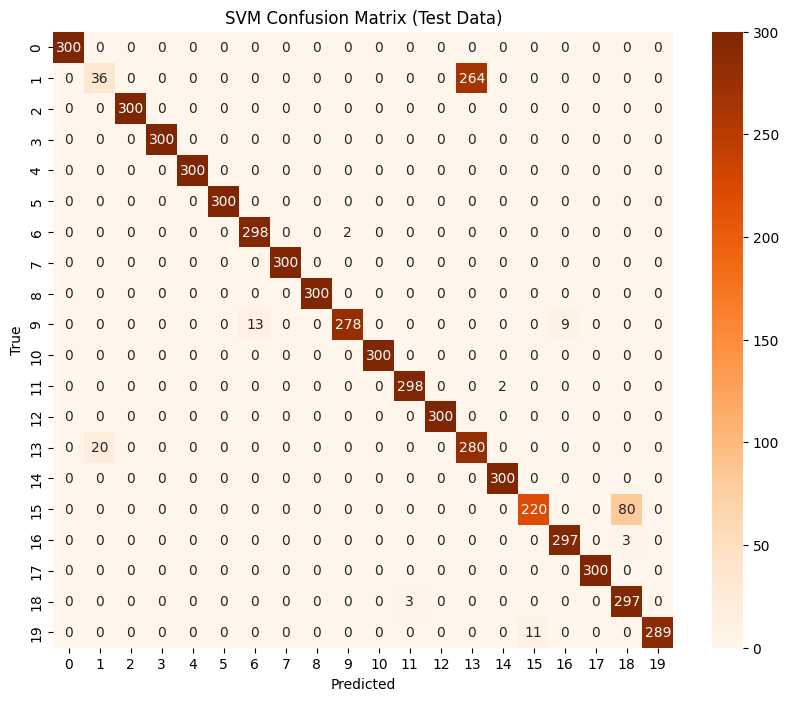

In [11]:
# Apply same scaler used during training
scaler = StandardScaler()
test_features_scaled = scaler.fit_transform(test_features)  # Fit on test data

# Predict using SVM
svm_test_preds = predict_svm(svm_model, test_features_scaled)

# Evaluate
accuracy = accuracy_score(test_labels, svm_test_preds)
print(f"SVM Test Accuracy: {accuracy * 100:.2f}%")

# Print classification report
print("\nSVM Classification Report:")
print(classification_report(test_labels, svm_test_preds))

# Confusion Matrix
cm_svm = confusion_matrix(test_labels, svm_test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM Confusion Matrix (Test Data)")
plt.show()

### ResNet18 Evaluation on Test Data

ResNet18 Test Accuracy: 98.98%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       300
           1       1.00      1.00      1.00       300
           2       1.00      1.00      1.00       300
           3       1.00      1.00      1.00       300
           4       1.00      1.00      1.00       300
           5       1.00      1.00      1.00       300
           6       1.00      1.00      1.00       300
           7       1.00      1.00      1.00       300
           8       1.00      1.00      1.00       300
           9       1.00      1.00      1.00       300
          10       1.00      0.99      1.00       300
          11       1.00      1.00      1.00       300
          12       1.00      1.00      1.00       300
          13       1.00      1.00      1.00       300
          14       1.00      0.90      0.95       300
          15       1.00      1.00      1.00       300
          16       0.91   

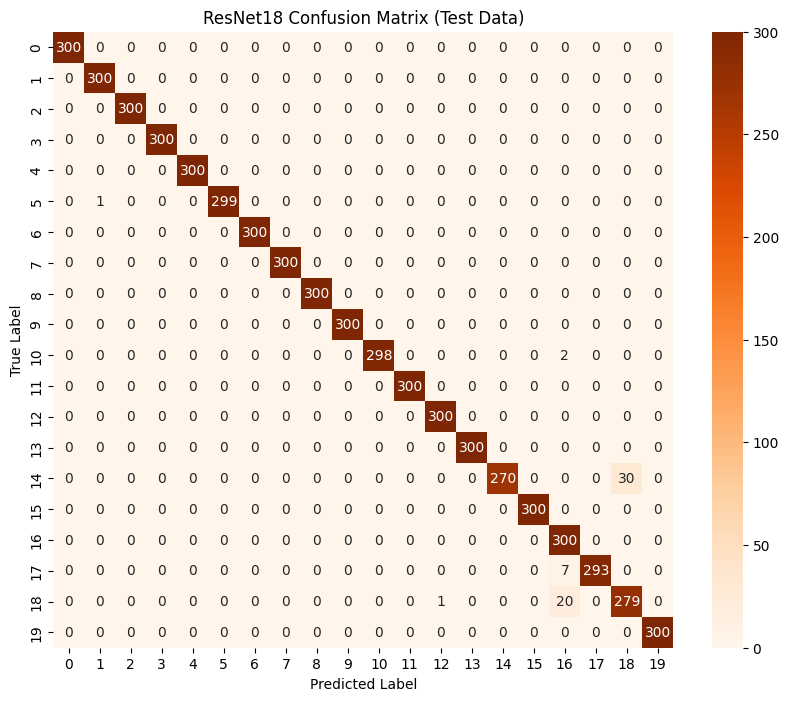

In [13]:
# Predict on test images
resnet_test_preds, resnet_test_labels = predict_resnet18(resnet_model, test_dir)  # test_dir is path to test folder

# Accuracy
accuracy = accuracy_score(resnet_test_labels, resnet_test_preds)
print(f"ResNet18 Test Accuracy: {accuracy * 100:.2f}%")

# Classification Report
print("\nClassification Report:")
print(classification_report(resnet_test_labels, resnet_test_preds))

# Confusion Matrix
cm = confusion_matrix(resnet_test_labels, resnet_test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet18 Confusion Matrix (Test Data)")
plt.show()


## 6. Evaluation and Results

To evaluate the performance of each classification model — **KNN**, **SVM**, and **ResNet18** — we used the held-out **test dataset** consisting of **6,000 images** (300 per class across 20 classes). 
Each model was trained on a **training set of 18,000 images** (900 per class) and evaluated using accuracy, classification reports, and confusion matrices.

### 🔍 Model-wise Summary

| Model       | Train Accuracy | Test Accuracy | Observations |
|-------------|----------------|---------------|--------------|
| **KNN**     | 99.37%         | 93.12%        | High training accuracy, but performance degraded significantly for some test classes like Class 1 and 13. |
| **SVM**     | 98.03%         | 93.22%        | Slightly lower training accuracy than KNN but similar test accuracy. Class 1 and 13 were also difficult for SVM to classify. |
| **ResNet18**| **99.57%**     | **98.98%**    | Achieved highest test accuracy. Minimal overfitting. Consistently high precision and recall across nearly all classes. |

### 📊 Key Observations

- **KNN** showed strong overfitting characteristics. While it performed well on most classes during training, it struggled with certain classes during testing (notably Class 1, 13, 15, and 19).
- **SVM** was more stable than KNN but still suffered in certain classes, particularly **Class 1** (*f1-score 0.20*).
- **ResNet18**, a deep CNN model, generalized best and demonstrated high robustness, even for previously problematic classes.

### 📉 Confusion Matrices

Insights from the confusion matrices revealed:

- **KNN**: Most errors occurred between visually similar gestures like **Classes 1 & 13**.
- **SVM**: Misclassified samples were more skewed for **Class 1 and Class 13**, consistent with the classification report.
- **ResNet18**: Confusion was minimal. Only a few misclassifications observed, mostly around **Classes 14, and 18**.

---

## 7. Conclusion

## Step 7: Conclusion

This project evaluated three different classification approaches for **static hand gesture recognition**:

- **Traditional Machine Learning models** (**KNN** and **SVM**) using handcrafted features such as **Hu Moments** and **convexity defects**.
- **Deep Learning model** (**ResNet18**) trained on raw image pixels with **data augmentation** and **multi-threaded data loading**.

### 🏁 Final Takeaways

- **ResNet18** significantly outperformed KNN and SVM in terms of both **accuracy** and **robustness**. Its ability to learn hierarchical features from images made it well-suited for this task.
- **KNN and SVM**, while effective on training data, struggled to generalize well on the test set due to their reliance on hand-crafted features.
- The best **trade-off between performance and scalability** was offered by ResNet18, especially after resizing images to **112×112** to reduce computation time.

### 📌 Future Improvements

- Fine-tune **ResNet18** with more epochs and learning rate scheduling.
- Try other architectures like **MobileNet** or **EfficientNet** for better speed-performance balance.
- Perform **data augmentation** to boost generalization even more.
- Use real-time **video or gesture sequence recognition** (e.g., with **RNNs** or **LSTMs**) for dynamic gesture datasets.